# 6. Results Summary

Final tables and charts for the thesis, for both parts of the title (**prediction of the produced power** and **anomaly detection**) and both systems (4: analysed in depth; 1283: generalization). Nothing is trained here: the notebook only reads what notebooks 4 and 5 (and their system-1283 copies) saved in `artifacts/metrics/`, so run those first.

Sections: 6.1 estimation, 6.2 forecasting, 6.3 best model per task, 6.4 anomaly detection, 6.5 thesis charts, 6.6 conclusions. Every table is also saved as `artifacts/metrics/thesis_table_<n>_<name>.csv`.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "artifacts" / "metrics").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the thesis project root.")

SYSTEMS = [4, 1283]
METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
MODELS = ["Linear Regression", "Decision Tree", "Random Forest", "MLP", "XGBoost"]
SYSTEM_COLORS = {4: "tab:blue", 1283: "tab:orange"}


def read_metric(system, name, **kwargs):
    path = METRICS_DIR / f"system_{system}_{name}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"{path.name} is missing; run notebooks 4 and 5 for system {system} first.")
    return pd.read_csv(path, **kwargs)


evaluation = pd.concat({s: read_metric(s, "eval_metrics_all_tasks", index_col=["task", "model"]) for s in SYSTEMS},
                       names=["system"])
best_models = pd.concat({s: read_metric(s, "eval_best_models", index_col="task") for s in SYSTEMS}, names=["system"])
anomaly = pd.concat({s: read_metric(s, "anomaly_summary", index_col="detector").drop(columns="system")
                     for s in SYSTEMS}, names=["system"])
configs = pd.concat({s: read_metric(s, "feature_configs", index_col="config") for s in SYSTEMS}, names=["system"])


def save_table(table, number, name):
    path = METRICS_DIR / f"thesis_table_{number}_{name}.csv"
    table.to_csv(path)
    print(f"Saved to: {path.name}")


display(configs[["train_rows", "test_rows", "train_start", "test_end"]])

train_rows  test_rows          train_start  \
system config                                                    
4      endogenous      1059458     264865  2007-08-26 10:30:00   
       exogenous       1059458     264865  2007-08-26 10:30:00   
       forecast_1h       93909      21011  2007-08-27 06:00:00   
       forecast_3h       93812      20884  2007-08-27 06:00:00   
1283   endogenous        54947      10980  2015-01-06 07:48:00   
       exogenous         54947      10980  2015-01-06 07:48:00   
       forecast_1h        3234        403  2015-01-05 07:30:00   
       forecast_3h        3205        403  2015-01-05 07:30:00   

                               test_end  
system config                            
4      endogenous   2023-01-31 16:17:00  
       exogenous    2023-01-31 16:17:00  
       forecast_1h  2023-01-31 16:45:00  
       forecast_3h  2023-01-31 16:45:00  
1283   endogenous   2015-12-31 16:08:00  
       exogenous    2015-12-31 16:08:00  
       forecast_1h  2015-12-31 16:00:00  
       forecast_3h  2015-12-31 16:00:00

## 6.1 Estimation of the current power

Power at the same minute from same-time measurements. **Endogenous** = irradiance + module temperature (plant sensors); **exogenous** = ambient temperature + calendar (no irradiance sensor). Test rows are normal operation only (rule faults excluded). System 4: chronological 80/20 split (test 2016-2023); system 1283: last 7 days of every month of 2015. nRMSE = RMSE as % of the mean test power, so the two systems (1.3 kW vs ~250 kW) can be compared.

In [2]:
COLUMNS = ["test_RMSE", "nRMSE_%", "test_R2", "cv_RMSE_mean", "cv_RMSE_std"]
estimation = (evaluation.loc[(slice(None), ["Estimation, endogenous", "Estimation, exogenous"], MODELS), COLUMNS]
              .rename(columns={"test_RMSE": "RMSE_W", "test_R2": "R2"}))
save_table(estimation, 1, "estimation")
display(estimation.unstack("system").swaplevel(axis=1).sort_index(axis=1, level=0)
        [[(s, c) for s in SYSTEMS for c in ("RMSE_W", "nRMSE_%", "R2")]].round(3))

Saved to: thesis_table_1_estimation.csv


system                                       4                         1283  \
                                           RMSE_W nRMSE_%     R2     RMSE_W   
task                   model                                                  
Estimation, endogenous Linear Regression   32.025   6.543  0.989  11264.646   
                       Decision Tree       29.098   5.945  0.991  10917.768   
                       Random Forest       28.904   5.905  0.991  10615.678   
                       MLP                 28.290   5.780  0.991  10194.384   
                       XGBoost             28.874   5.899  0.991  11119.410   
Estimation, exogenous  Linear Regression  223.050  45.569  0.450  35017.224   
                       Decision Tree      232.003  47.398  0.405  39570.996   
                       Random Forest      222.785  45.514  0.451  34955.323   
                       MLP                217.159  44.365  0.478  33651.051   
                       XGBoost            222.247  45.405  0.454  36709.841   

system                                                   
                                         nRMSE_%     R2  
task                   model                             
Estimation, endogenous Linear Regression  12.560  0.959  
                       Decision Tree      12.173  0.962  
                       Random Forest      11.837  0.964  
                       MLP                11.367  0.966  
                       XGBoost            12.398  0.960  
Estimation, exogenous  Linear Regression  39.045  0.604  
                       Decision Tree      44.122  0.494  
                       Random Forest      38.975  0.605  
                       MLP                37.521  0.634  
                       XGBoost            40.932  0.565

## 6.2 Forecasting 1 h and 3 h ahead

Power of a 15-minute slot 1 h or 3 h after the latest observation, compared with three references that need no training: persistence, same time yesterday and clear-sky persistence (the clear-sky index kept constant). Skill = 1 − RMSE / RMSE of the reference; above 0 means better than the reference. The system-1283 forecasting test set is small (403 slots, 17-19 days), so its ranking is indicative.

In [3]:
COLUMNS = ["test_RMSE", "nRMSE_%", "test_R2", "skill_vs_persistence", "skill_vs_clear_sky"]
forecasting = (evaluation.loc[(slice(None), ["Forecast 1 h", "Forecast 3 h"]), COLUMNS]
               .rename(columns={"test_RMSE": "RMSE_W", "test_R2": "R2"}))
save_table(forecasting, 2, "forecasting")
for task in ("Forecast 1 h", "Forecast 3 h"):
    print(task)
    display(forecasting.xs(task, level="task").unstack("system")
            [[(c, s) for s in SYSTEMS for c in ("nRMSE_%", "R2", "skill_vs_persistence", "skill_vs_clear_sky")]]
            .round(3))

Saved to: thesis_table_2_forecasting.csv
Forecast 1 h


,nRMSE_%,R2,skill_vs_persistence,skill_vs_clear_sky,nRMSE_%,R2,skill_vs_persistence,skill_vs_clear_sky
system,4,4,4,4,1283,1283,1283,1283
model,,,,,,,,
Clear-sky persistence,40.754,0.735,0.220,0.000,25.818,0.851,0.344,0.000
Decision Tree,36.006,0.793,0.311,0.117,32.276,0.767,0.180,-0.250
Linear Regression,39.430,0.752,0.245,0.032,25.572,0.854,0.350,0.010
MLP,34.919,0.806,0.332,0.143,24.304,0.868,0.382,0.059
Persistence,52.239,0.565,0.000,-0.282,39.352,0.654,0.000,-0.524
Random Forest,34.544,0.810,0.339,0.152,28.032,0.824,0.288,-0.086
Same time yesterday,68.870,0.244,-0.318,-0.690,48.598,0.472,-0.235,-0.882
XGBoost,34.749,0.808,0.335,0.147,31.887,0.773,0.190,-0.235


Forecast 3 h


,nRMSE_%,R2,skill_vs_persistence,skill_vs_clear_sky,nRMSE_%,R2,skill_vs_persistence,skill_vs_clear_sky
system,4,4,4,4,1283,1283,1283,1283
model,,,,,,,,
Clear-sky persistence,58.499,0.455,0.404,0.000,31.206,0.782,0.607,0.000
Decision Tree,46.301,0.659,0.528,0.209,45.913,0.528,0.422,-0.471
Linear Regression,50.480,0.594,0.486,0.137,32.809,0.759,0.587,-0.051
MLP,44.419,0.686,0.547,0.241,31.358,0.780,0.605,-0.005
Persistence,98.124,-0.533,0.000,-0.677,79.463,-0.414,0.000,-1.546
Random Forest,44.537,0.684,0.546,0.239,38.481,0.668,0.516,-0.233
Same time yesterday,68.866,0.245,0.298,-0.177,48.537,0.472,0.389,-0.555
XGBoost,44.941,0.678,0.542,0.232,41.801,0.609,0.474,-0.340


## 6.3 Best model per task

Chosen in notebook 4 (section 4.8): among the models statistically tied with the most accurate one (paired block bootstrap over test days), the fastest to train.

In [4]:
best = best_models[["most_accurate", "tied_models", "chosen", "test_RMSE", "test_R2", "fit_seconds", "model_size_kb"]]
save_table(best, 3, "best_models")
with pd.option_context("display.max_colwidth", None):
    display(best.round(3))

Saved to: thesis_table_3_best_models.csv


most_accurate  \
system task                                    
4      Estimation, endogenous            MLP   
       Estimation, exogenous             MLP   
       Forecast 1 h            Random Forest   
       Forecast 3 h                      MLP   
1283   Estimation, endogenous            MLP   
       Estimation, exogenous             MLP   
       Forecast 1 h                      MLP   
       Forecast 3 h                      MLP   

                                                                  tied_models  \
system task                                                                     
4      Estimation, endogenous                                             MLP   
       Estimation, exogenous                                              MLP   
       Forecast 1 h                                             Random Forest   
       Forecast 3 h                                        Random Forest, MLP   
1283   Estimation, endogenous                              Random Forest, MLP   
       Estimation, exogenous   Linear Regression, Random Forest, MLP, XGBoost   
       Forecast 1 h                                    Linear Regression, MLP   
       Forecast 3 h                           Linear Regression, MLP, XGBoost   

                                          chosen  test_RMSE  test_R2  \
system task                                                            
4      Estimation, endogenous                MLP     28.290    0.991   
       Estimation, exogenous                 MLP    217.159    0.478   
       Forecast 1 h                Random Forest    140.033    0.810   
       Forecast 3 h                Random Forest    180.401    0.684   
1283   Estimation, endogenous      Random Forest  10615.678    0.964   
       Estimation, exogenous   Linear Regression  35017.224    0.604   
       Forecast 1 h            Linear Regression  21230.800    0.854   
       Forecast 3 h            Linear Regression  27295.382    0.759   

                               fit_seconds  model_size_kb  
system task                                                
4      Estimation, endogenous        8.808         62.088  
       Estimation, exogenous        84.029         68.560  
       Forecast 1 h                  5.078      10104.886  
       Forecast 3 h                  4.536      10260.276  
1283   Estimation, endogenous        0.571       7215.464  
       Estimation, exogenous         0.005          0.684  
       Forecast 1 h                  0.002          0.926  
       Forecast 3 h                  0.002          0.926

## 6.4 Anomaly detection

Three detectors (notebook 5): the **rule** (strong sun, power below 0.5 × k × irradiance; the cleaning rule of notebook 1), the **residual** detector (actual vs expected power of the best endogenous model, 15-minute median, thresholds median ± 5 robust σ from the training period) and an **Isolation Forest** (unsupervised, 5% prior). Real data: recall on full outages, the only type the rule labels judge without circularity. Synthetic events injected into clean test days: full outages, partial losses (10-40%) and sensor faults (irradiance reading 20-40% low); false alarms on clean days that received no event.

In [5]:
COLUMNS = {"real_recall_full_outage_%": "real full outage recall %",
           "synthetic_full_outage_recall_%": "synthetic full outage recall %",
           "synthetic_partial_loss_recall_%": "synthetic partial loss recall %",
           "synthetic_sensor_fault_recall_%": "synthetic sensor fault recall %",
           "synthetic_false_alarm_%": "false alarms %",
           "test_flagged_%": "test rows flagged %",
           "synthetic_events_per_type": "events per type",
           "synthetic_injection_days": "injection days"}
anomaly_table = anomaly[list(COLUMNS)].rename(columns=COLUMNS)
save_table(anomaly_table, 4, "anomaly_detection")
display(anomaly_table.round(1))
display(anomaly[["reference_model"]].groupby(level="system").first())

Saved to: thesis_table_4_anomaly_detection.csv


real full outage recall %  synthetic full outage recall %  \
system detector                                                              
4      rule                          100.0                           100.0   
       residual                       99.5                           100.0   
       iforest                        78.3                            99.0   
1283   rule                          100.0                           100.0   
       residual                      100.0                           100.0   
       iforest                        10.2                            66.7   

                 synthetic partial loss recall %  \
system detector                                    
4      rule                                  0.0   
       residual                             58.0   
       iforest                              18.0   
1283   rule                                  0.0   
       residual                             30.3   
       iforest                              36.4   

                 synthetic sensor fault recall %  false alarms %  \
system detector                                                    
4      rule                                  0.0             0.0   
       residual                             97.0             4.9   
       iforest                              19.0             0.8   
1283   rule                                  0.0             0.0   
       residual                             45.5             2.2   
       iforest                              72.7             3.5   

                 test rows flagged %  events per type  injection days  
system detector                                                        
4      rule                      6.6              100             322  
       residual                 11.0              100             322  
       iforest                   4.5              100             322  
1283   rule                     32.9               33              10  
       residual                 34.7               33              10  
       iforest                   6.4               33              10

,reference_model
system,
4,MLP
1283,Random Forest


## 6.5 Thesis charts

Figure A: error of every model per task and system (nRMSE). Figure B: forecast skill of the best model against the three references. Figure C: anomaly detection, event recall per type and false alarms, per detector and system.

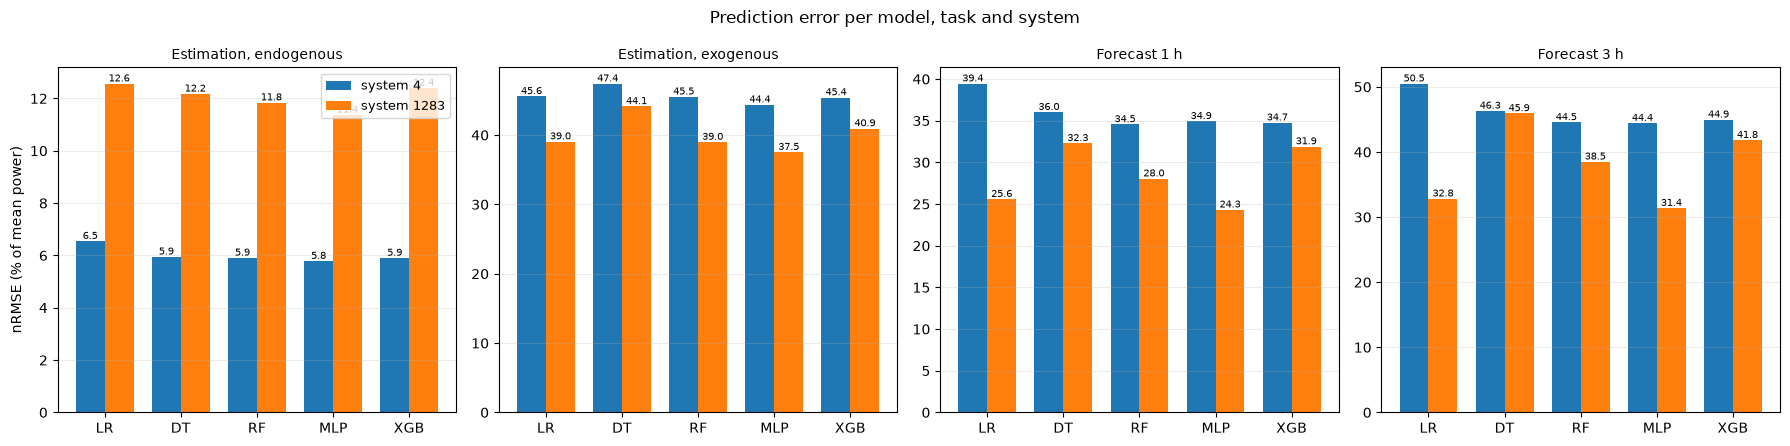

Saved to: thesis_figure_A_nrmse_per_task.png


In [6]:
TASKS = ["Estimation, endogenous", "Estimation, exogenous", "Forecast 1 h", "Forecast 3 h"]
FIGURE_A_PATH = METRICS_DIR / "thesis_figure_A_nrmse_per_task.png"
fig, axes = plt.subplots(1, len(TASKS), figsize=(18, 4.5), sharey=False)
width = 0.38
positions = np.arange(len(MODELS))
for ax, task in zip(axes, TASKS):
    for offset, system in zip((-width / 2, width / 2), SYSTEMS):
        values = evaluation.loc[(system, task, MODELS), "nRMSE_%"].to_numpy()
        bars = ax.bar(positions + offset, values, width, color=SYSTEM_COLORS[system], label=f"system {system}")
        ax.bar_label(bars, fmt="%.1f", fontsize=7)
    ax.set_xticks(positions, ["LR", "DT", "RF", "MLP", "XGB"])
    ax.set_title(task, fontsize=10)
    ax.grid(True, axis="y", alpha=0.25)
axes[0].set_ylabel("nRMSE (% of mean power)")
axes[0].legend(fontsize=9)
fig.suptitle("Prediction error per model, task and system")
fig.tight_layout()
fig.savefig(FIGURE_A_PATH, dpi=160)
plt.show()
print(f"Saved to: {FIGURE_A_PATH.name}")

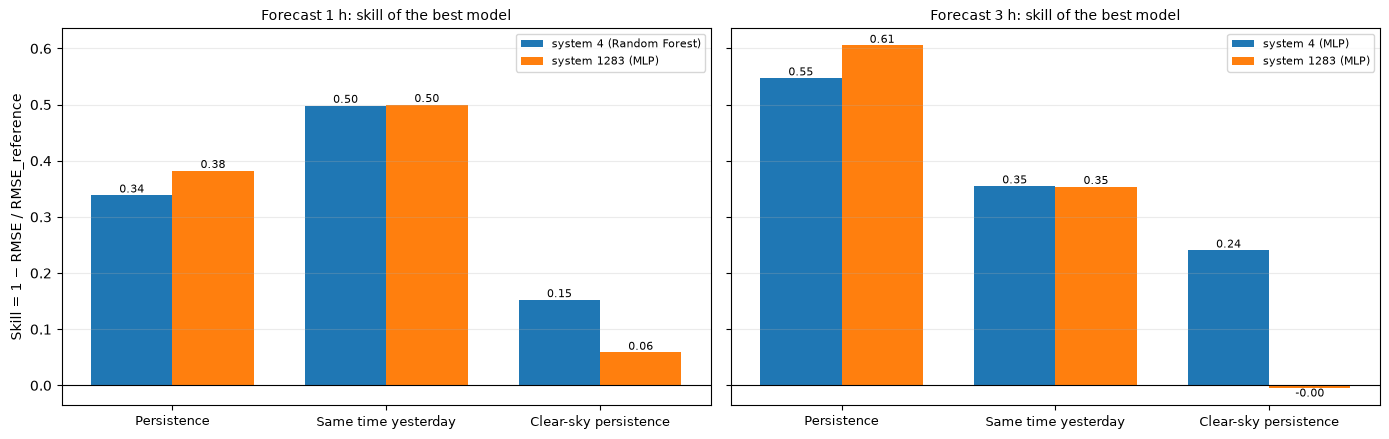

Saved to: thesis_figure_B_forecast_skill.png


In [7]:
FIGURE_B_PATH = METRICS_DIR / "thesis_figure_B_forecast_skill.png"
REFERENCES = ["Persistence", "Same time yesterday", "Clear-sky persistence"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
positions = np.arange(len(REFERENCES))
for ax, task in zip(axes, ("Forecast 1 h", "Forecast 3 h")):
    for offset, system in zip((-width / 2, width / 2), SYSTEMS):
        table = evaluation.loc[(system, task)]
        best_rmse = table.loc[MODELS, "test_RMSE"].min()
        skill = [1 - best_rmse / table.loc[reference, "test_RMSE"] for reference in REFERENCES]
        bars = ax.bar(positions + offset, skill, width, color=SYSTEM_COLORS[system],
                      label=f"system {system} ({table.loc[MODELS, 'test_RMSE'].idxmin()})")
        ax.bar_label(bars, fmt="%.2f", fontsize=8)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(positions, REFERENCES, fontsize=9)
    ax.set_title(f"{task}: skill of the best model", fontsize=10)
    ax.grid(True, axis="y", alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Skill = 1 − RMSE / RMSE_reference")
fig.tight_layout()
fig.savefig(FIGURE_B_PATH, dpi=160)
plt.show()
print(f"Saved to: {FIGURE_B_PATH.name}")

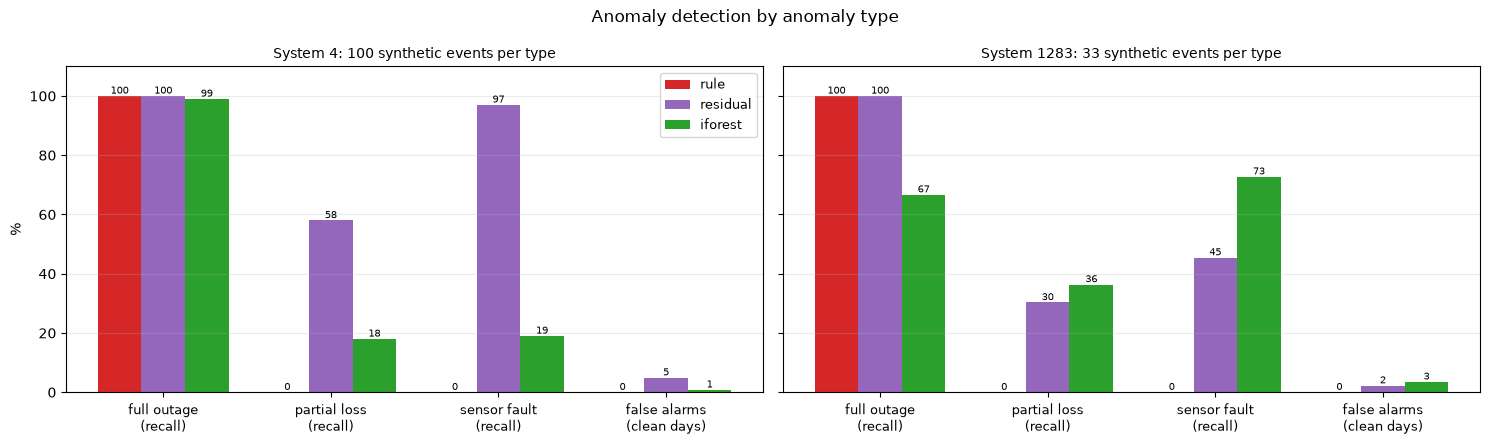

Saved to: thesis_figure_C_anomaly_detection.png


In [8]:
FIGURE_C_PATH = METRICS_DIR / "thesis_figure_C_anomaly_detection.png"
DETECTORS = ["rule", "residual", "iforest"]
DETECTOR_COLORS = {"rule": "tab:red", "residual": "tab:purple", "iforest": "tab:green"}
MEASURES = {"synthetic_full_outage_recall_%": "full outage", "synthetic_partial_loss_recall_%": "partial loss",
            "synthetic_sensor_fault_recall_%": "sensor fault", "synthetic_false_alarm_%": "false alarms"}
fig, axes = plt.subplots(1, len(SYSTEMS), figsize=(15, 4.5), sharey=True)
width = 0.26
positions = np.arange(len(MEASURES))
for ax, system in zip(axes, SYSTEMS):
    for offset, detector in zip((-width, 0, width), DETECTORS):
        values = anomaly.loc[(system, detector), list(MEASURES)].to_numpy(dtype=float)
        bars = ax.bar(positions + offset, values, width, color=DETECTOR_COLORS[detector], label=detector)
        ax.bar_label(bars, fmt="%.0f", fontsize=7)
    events = int(anomaly.loc[(system, "rule"), "synthetic_events_per_type"])
    ax.set_xticks(positions, [f"{m}\n(recall)" if m != "false alarms" else "false alarms\n(clean days)"
                              for m in MEASURES.values()], fontsize=9)
    ax.set_title(f"System {system}: {events} synthetic events per type", fontsize=10)
    ax.grid(True, axis="y", alpha=0.25)
    ax.set_ylim(0, 110)
axes[0].set_ylabel("%")
axes[0].legend(fontsize=9)
fig.suptitle("Anomaly detection by anomaly type")
fig.tight_layout()
fig.savefig(FIGURE_C_PATH, dpi=160)
plt.show()
print(f"Saved to: {FIGURE_C_PATH.name}")

## 6.6 Conclusions

**Prediction of the produced power**

1. **On-site irradiance is what makes the power predictable.** With irradiance and module temperature (endogenous) the current power is estimated with R² 0.991 (nRMSE 5.8%) on system 4 and 0.966 (11.4%) on system 1283. Without them (ambient temperature + calendar) R² drops to 0.48 and 0.63: the calendar gives the sun's path, but only the irradiance sensor sees the clouds. The gap is 7.7× (system 4) and 3.3× (system 1283) in RMSE.
2. **Model choice matters much less than inputs.** For system-4 endogenous estimation the four non-linear models are within 1 W (3%) of each other and Linear Regression is ~13% worse; the MLP is the most accurate in 7 of the 8 task/system combinations. With fewer rows (system 1283) more models are statistically tied, and the simplest tied model is often enough (Linear Regression for 1283 forecasting).
3. **Forecasting is useful but much harder than estimation.** Error grows with the horizon (system 4: R² 0.99 estimation → 0.81 at 1 h → 0.69 at 3 h). Every model beats plain persistence (skill 0.33-0.61), but the honest reference is clear-sky persistence: system 4 keeps a skill of 0.15 (1 h) and 0.24 (3 h), system 1283 only 0.06 and 0.00, because ~3,000 training slots are too few to learn more than the daily clear-sky shape.
4. **Evaluation design changes the numbers.** A random split looks 9-13% better than a chronological one on minute data (neighbouring minutes leak), and a few fault minutes dominate the error (0.7% of rows caused 69% of the squared error before the fault flagging). The thesis results use time-ordered splits and normal rows only.

**Anomaly detection**

5. **The rule is enough for full outages, and only for them.** Strong sun with almost no power is caught by the rule, by the residual detector (99.5-100%) and mostly by the Isolation Forest. But the rule caught 0% of the synthetic partial losses (10-40%) and sensor faults: by construction it cannot see a loss above 50% of normal, or a wrong irradiance reading.
6. **The power model is the best anomaly detector.** Comparing the actual power with the power the endogenous model expects finds 58% of partial losses on system 4 (82-100% for losses of 20% or more) and 97% of sensor faults, at ~5% false alarms on clean days. The threshold is a trade-off (3σ: 86% of partial losses at 10% false alarms; 8σ: 18% at 2%). Real examples include a snow-capped December day (power held at ~70% of expected for hours) that the rule flags only in the early morning.
7. **Detection quality follows prediction quality.** On system 1283 the reference model is less precise (σ of the residual 0.072 vs 0.044), so the same 5σ rule only sees losses above ~35% (30% of partial losses, 45% of sensor faults). The Isolation Forest is weaker than the residual detector on system 4 but complements it on 1283; with only 10 clean test days (33 events per type) the 1283 numbers are indicative.
8. **Overall:** the same pipeline (cleaning, rule flags, endogenous model, residual detector) works on two very different systems, a 1.3 kW site with 15 years of data and a ~250 kW inverter with one snowy year. The predictive model has two uses: it estimates and forecasts the power, and it is the reference of normal behaviour that the anomaly detection is built on.